# Estimating Parameters of  Bradley terry Model via Maximum Likelihood Estimation.

In [16]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import choix
import time 
import numpy as np
import torch
np.random.seed(42) #ysbh

In [4]:
items=["car", "taxi", "bike", "bus", "walking"]
n_items =len(items)
true_weights= np.array([0.40,0.25,0.15,01.2,0.08])
true_params= np.log(true_weights)
true_params = true_params - np.mean(true_params)
print("True parameters:", np.round(true_params, 5))


True parameters: [ 0.39233 -0.07767 -0.5885   1.49094 -1.21711]


In [21]:
n_comparison = 1000
data =[]
for _ in range(n_comparison):
    i,j= np.random.choice(n_items, size =2, replace = False)
    prob_i_wins=np.exp(true_params[i])/(np.exp(true_params[i])+ np.exp(true_params[j]))
    if np.random.rand() < prob_i_wins:
        data.append((i,j))
    else:
        data.append((j,i))
print("Generated comparisons:")
for winner, loser in data:
    print(f"{items[winner]} > {items[loser]}")

df=pd.DataFrame(data)
df.head(20)



Generated comparisons:
walking > car
taxi > bike
car > walking
taxi > walking
bus > taxi
bus > taxi
bus > walking
taxi > bike
car > taxi
car > bike
bike > taxi
car > taxi
bus > bike
taxi > bike
car > taxi
car > bike
bike > walking
bus > walking
bike > walking
bike > car
bus > car
car > bike
walking > taxi
bus > walking
taxi > walking
walking > bike
bus > walking
bus > bike
car > taxi
bus > walking
car > walking
bus > bike
bus > walking
bus > bike
walking > bus
bus > taxi
bus > bike
bus > bike
bike > taxi
taxi > bike
bus > car
taxi > car
walking > bike
bus > taxi
bus > walking
walking > bus
taxi > bike
bus > taxi
walking > bike
car > bike
bus > car
taxi > bus
bike > walking
bus > walking
car > bike
bus > taxi
bus > bike
taxi > walking
bus > walking
bus > bike
bus > bike
bike > bus
bus > taxi
bus > car
taxi > bike
car > bus
walking > bike
bike > walking
car > bus
bus > bike
car > bike
taxi > walking
bike > walking
car > walking
taxi > bike
bike > taxi
car > walking
bus > bike
car > bike


,0,1
0,4,0
1,1,2
2,0,4
3,1,4
4,3,1
5,3,1
6,3,4
7,1,2
8,0,1
9,0,2


In [7]:
data_arr = np.array(data)
wins = np.bincount(data_arr[:, 0], minlength=n_items)
appearances = np.bincount(data_arr.flatten(), minlength=n_items)
win_rate = wins / appearances
print(f"{'Item':<10}{'Wins':>6}{'Appearances':>14}{'Win Rate':>12}{'True Weight':>14}")
print("-" * 56)
for idx, name in enumerate(items):
    print(f"{name:<10}{wins[idx]:>6}{appearances[idx]:>14}"
          f"{win_rate[idx]:>12.3f}{true_weights[idx]:>14.3f}")

Item        Wins   Appearances    Win Rate   True Weight
--------------------------------------------------------
car          266           414       0.643         0.400
taxi         175           393       0.445         0.250
bike         139           410       0.339         0.150
bus          341           402       0.848         1.200
walking       79           381       0.207         0.080


In [8]:
estimated_params = choix.ilsr_pairwise(
    n_items=n_items,
    data=data,
    alpha=0.01   
)

In [9]:
print("True parameters:     ", np.round(true_params, 3))
print("Estimated parameters:", np.round(estimated_params, 3))


True parameters:      [ 0.392 -0.078 -0.588  1.491 -1.217]
Estimated parameters: [ 0.583 -0.29  -0.6    1.516 -1.209]


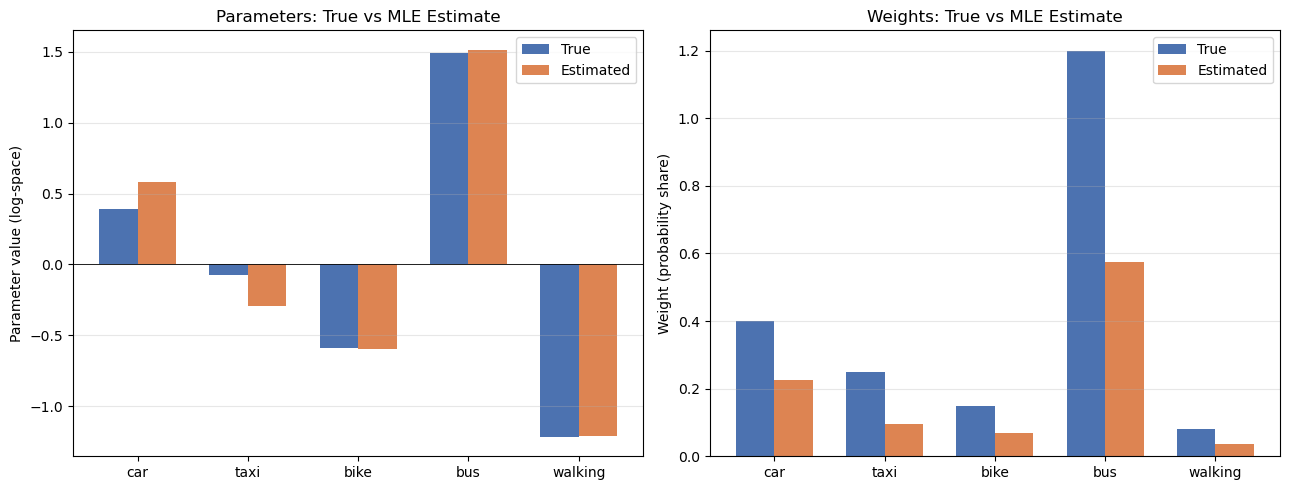

Mean absolute error on parameters: 0.0895
Mean absolute error on weights:    0.2160


In [11]:
estimated_weights = np.exp(estimated_params)
estimated_weights = estimated_weights / estimated_weights.sum()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
x = np.arange(n_items)
bar_width = 0.35
axes[0].bar(x - bar_width/2, true_params,      bar_width, label="True",      color="#4C72B0")
axes[0].bar(x + bar_width/2, estimated_params, bar_width, label="Estimated", color="#DD8452")
axes[0].axhline(0, color="black", linewidth=0.6)
axes[0].set_xticks(x)
axes[0].set_xticklabels(items)
axes[0].set_ylabel("Parameter value (log-space)")
axes[0].set_title("Parameters: True vs MLE Estimate")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)
axes[1].bar(x - bar_width/2, true_weights,      bar_width, label="True",      color="#4C72B0")
axes[1].bar(x + bar_width/2, estimated_weights, bar_width, label="Estimated", color="#DD8452")
axes[1].set_xticks(x)
axes[1].set_xticklabels(items)
axes[1].set_ylabel("Weight (probability share)")
axes[1].set_title("Weights: True vs MLE Estimate")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
param_mae  = np.mean(np.abs(true_params  - estimated_params))
weight_mae = np.mean(np.abs(true_weights - estimated_weights))
print(f"Mean absolute error on parameters: {param_mae:.4f}")
print(f"Mean absolute error on weights:    {weight_mae:.4f}")

True parameters:            [ 0.392 -0.078 -0.588  1.491 -1.217]
choix I-LSR:                [ 0.583 -0.29  -0.6    1.516 -1.209]
Gradient descent (scratch): [ 0.582 -0.289 -0.599  1.513 -1.206]

Mean absolute error (GD vs true):  0.08895
Mean Absolute error (GD vs choix): 0.00140


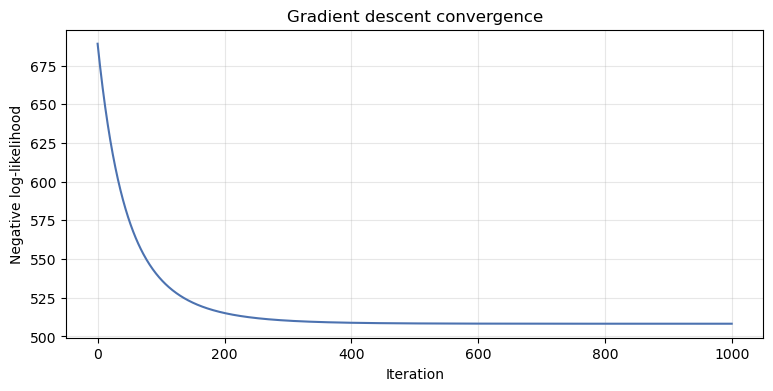

In [15]:
data_arr = np.array(data)
winners = data_arr[:, 0]   
losers  = data_arr[:, 1]   
def sigmoid(x):
    """Numerically stable sigmoid never overflows for large |x|."""
    return np.where(x >= 0,
                    1.0 / (1.0 + np.exp(-x)),
                    np.exp(x) / (1.0 + np.exp(x)))
def neg_log_likelihood(params):
    """Negative log-likelihood of the Bradley-Terry model.
    We minimize this = maximize log-likelihood."""
    diff = params[winners] - params[losers]      
    return np.sum(np.log1p(np.exp(-diff)))        
def gradient_of_nll(params):
    p_winner_wins = sigmoid(params[winners] - params[losers])
    residual = 1.0 - p_winner_wins    
    grad = np.zeros(n_items)
    np.add.at(grad, winners, -residual)
    np.add.at(grad, losers,   residual)
    return grad / len(winners)      
params_gd     = np.zeros(n_items)   
learning_rate = 0.1
n_iterations  = 1000
nll_history = []
for step in range(n_iterations):
    g = gradient_of_nll(params_gd)
    params_gd = params_gd - learning_rate * g
    params_gd = params_gd - np.mean(params_gd)
    nll_history.append(neg_log_likelihood(params_gd))
print(f"True parameters:            {np.round(true_params,      3)}")
print(f"choix I-LSR:                {np.round(estimated_params, 3)}")
print(f"Gradient descent (scratch): {np.round(params_gd,        3)}")
print()
print(f"Mean absolute error (GD vs true):  {np.mean(np.abs(params_gd - true_params)):.5f}")
print(f"Mean Absolute error (GD vs choix): {np.mean(np.abs(params_gd - estimated_params)):.5f}")
plt.figure(figsize=(9, 4))
plt.plot(nll_history, color="#4C72B0")
plt.xlabel("Iteration")
plt.ylabel("Negative log-likelihood")
plt.title("Gradient descent convergence")
plt.grid(alpha=0.3)
plt.show()